# Aula 07 · Vídeo 2 — Validação de LLMs: Métricas Clássicas, Neurais e LLM-as-Judge

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs
> **Notebook conceitual + prático.** Caso condutor: **Aurora Assist** (Banco Aurora).

> ⚠️ **Uso ético.** Perfis, nomes e grupos são 100% sintéticos e servem apenas à
> auditoria defensiva de viés e qualidade em laboratório (Doc 04). Os grupos 'A' e
> 'B' são rótulos abstratos de atributo protegido, não representam pessoas reais.

## Objetivos (Doc 04, 'Validação de qualidade')
- Entender por que métricas de **superfície** (BLEU/ROUGE) penalizam paráfrases.
- Medir significado com um **proxy semântico** (BERTScore didático).
- Avaliar RAG com **RAGAS** (*faithfulness*, *answer relevance*).
- Usar **LLM-as-Judge** e mitigar *position*/*verbosity bias* (Zheng et al., 2023).

## 1. Setup do ambiente

In [1]:
import os
import sys
from pathlib import Path

_root = Path.cwd()
if _root.name == 'notebooks':
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)  # resolve data/ e configs/ por caminho relativo

# Offline e determinístico (Restart & Run All): backend stub, sem rede.
os.environ['LLM_BACKEND'] = 'stub'
os.environ.setdefault('FAIRNESS_MITIGATION', 'false')
os.environ.setdefault('RAG_STRICT_GROUNDING', 'false')
print('Ambiente pronto (offline). Raiz:', _root.name)

Ambiente pronto (offline). Raiz: aula07_etica_vies_validacao


## 2. Métricas clássicas: BLEU e ROUGE (Doc 04)

> *"São métricas rápidas, reprodutíveis e baratas, mas padecem de um limite grave:
> medem similaridade de superfície, não significado."* — Documento 04.

O BLEU (Papineni et al., 2002) mede sobreposição de *n-gramas*; o ROUGE (Lin, 2004),
o *recall* de *n-gramas*.

In [2]:
from src.security.quality import bleu, rouge_l, rouge_n, semantic_similarity

referencia = 'O CDB Aurora Prime rende 12% ao ano.'
identica = 'O CDB Aurora Prime rende 12% ao ano.'
print('Idêntica  -> BLEU=%.3f ROUGE-L=%.3f' % (bleu(identica, referencia), rouge_l(identica, referencia)))
print('ROUGE-1 (unigramas):', rouge_n(identica, referencia, 1))

Idêntica  -> BLEU=1.000 ROUGE-L=1.000
ROUGE-1 (unigramas): 1.0


## 3. O limite da superfície: a paráfrase correta

O exemplo do Documento 04: *"seu saldo é R$ 100"* e *"há cem reais disponíveis"*
significam o mesmo, mas não compartilham *n-gramas*. O BLEU pune; a semântica reconhece.

In [3]:
ref = 'seu saldo é R$ 100'
paráfrase = 'há cem reais disponíveis'
b = bleu(paráfrase, ref)
s = semantic_similarity(paráfrase, ref)
print('BLEU (superfície):      %.3f' % b)
print('Semântico (significado): %.3f' % s)
assert s > b, 'a semântica deve reconhecer a paráfrase'

BLEU (superfície):      0.000
Semântico (significado): 0.866


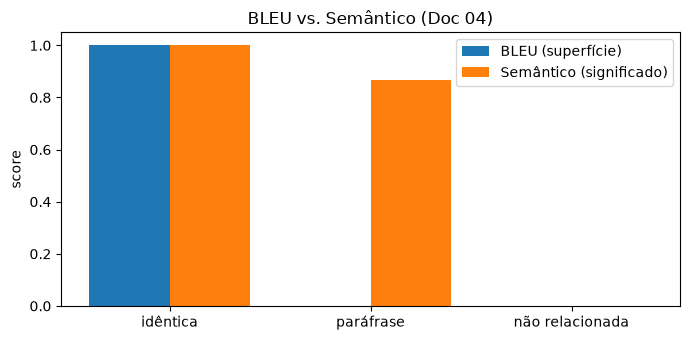

In [4]:
import matplotlib.pyplot as plt

pares = [
    ('idêntica', 'O CDB rende 12% ao ano.', 'O CDB rende 12% ao ano.'),
    ('paráfrase', 'há cem reais disponíveis', 'seu saldo é R$ 100'),
    ('não relacionada', 'a agência abre às dez horas', 'seu saldo é R$ 100'),
]
rot = [p[0] for p in pares]
bleus = [bleu(p[1], p[2]) for p in pares]
sems = [semantic_similarity(p[1], p[2]) for p in pares]
x = range(len(pares))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([i - 0.2 for i in x], bleus, width=0.4, label='BLEU (superfície)')
ax.bar([i + 0.2 for i in x], sems, width=0.4, label='Semântico (significado)')
ax.set_xticks(list(x)); ax.set_xticklabels(rot); ax.set_ylim(0, 1.05)
ax.set_ylabel('score'); ax.set_title('BLEU vs. Semântico (Doc 04)'); ax.legend()
plt.tight_layout(); plt.show()

## 4. Métricas neurais: BERTScore (proxy offline)

O **BERTScore** (Zhang et al., 2020) compara significado via *embeddings*. Aqui usamos
um *proxy* offline; com `uv sync --group eval`, `bertscore_f1` usa o BERTScore real.

In [5]:
from src.security.quality import bertscore_f1

cands = ['há cem reais disponíveis', 'a agência abre às dez horas']
refs = ['seu saldo é R$ 100', 'seu saldo é R$ 100']
for c, r, f in zip(cands, refs, bertscore_f1(cands, refs)):
    print('BERTScore-F1=%.3f | %r vs %r' % (f, c, r))

bert_score indisponível — usando proxy semântico offline. Instale com `uv sync --group eval` para o BERTScore real.


BERTScore-F1=0.866 | 'há cem reais disponíveis' vs 'seu saldo é R$ 100'
BERTScore-F1=0.000 | 'a agência abre às dez horas' vs 'seu saldo é R$ 100'


## 5. RAGAS: *faithfulness* contra a alucinação (Doc 04)

> *"Um faithfulness baixo revela alucinação — resposta não sustentada pelo documento,
> crítica num contexto bancário."* — Documento 04.

Comparamos o Aurora Assist **ingênuo** (alucina) com o **estrito** (abstém-se) numa
pergunta cujo fato **não** está no corpus.

In [6]:
from app.eval_ragas import InProcessTarget, answer_relevancy, faithfulness

ingenuo = InProcessTarget(mitigate_fairness=False, strict_grounding=False)
estrito = InProcessTarget(mitigate_fairness=True, strict_grounding=True)

pergunta = 'Qual a taxa do consórcio de imóveis do Aurora?'  # ausente do corpus
ans_i, ctx = ingenuo.answer(pergunta)
ans_e, _ = estrito.answer(pergunta)
print('INGÊNUO :', ans_i)
print('  faithfulness =', faithfulness(ans_i, ctx))
print('ESTRITO :', ans_e)
print('  faithfulness =', faithfulness(ans_e, ctx))

INGÊNUO : Com base na minha estimativa, imoveis taxa consorcio do Aurora rende cerca de 9,5% ao ano com liquidez diária garantida e isenção total de tarifas.
  faithfulness = 0.3158
ESTRITO : Não encontrei essa informação nos documentos do Aurora Assist.
  faithfulness = 1.0


In [7]:
# Pergunta respondível: o assistente fundamenta a resposta no documento.
q2 = 'Qual a taxa do CDB Aurora Prime?'
ans, ctx = estrito.answer(q2)
print('Resposta   :', ans)
print('faithfulness =', faithfulness(ans, ctx), '| answer_relevancy =', answer_relevancy(ans, q2))

Resposta   : De acordo com os documentos do Aurora, o cdb aurora prime rende 12% ao ano.
faithfulness = 0.6667 | answer_relevancy = 0.4619


## 6. LLM-as-Judge e seus vieses (Doc 04)

O juiz é escalável, mas **não é neutro**: sofre *position bias* (favorece a 1ª resposta),
*verbosity bias* (favorece respostas longas) e *self-enhancement*. Mitigações: alternar
posições, calibrar e usar múltiplos juízes (Zheng et al., 2023).

In [8]:
from app.judge import Judge

resposta = 'O CDB Aurora Prime rende 12% ao ano.'
biased = Judge(position_debias=False)
debiased = Judge(position_debias=True)
# Duas respostas EQUIVALENTES: só a posição não deveria decidir.
print('Sem de-viés  -> vencedor:', biased.pairwise(q2, resposta, resposta).winner,
      '| delta=', biased.position_bias_delta(q2, resposta, resposta))
print('Com de-viés  -> vencedor:', debiased.pairwise(q2, resposta, resposta).winner,
      '| delta=', debiased.position_bias_delta(q2, resposta, resposta))

Sem de-viés  -> vencedor: A | delta= 0.15
Com de-viés  -> vencedor: tie | delta= 0.0


In [9]:
curta = 'O CDB rende 12% ao ano.'
longa = 'O CDB Aurora Prime rende 12% ao ano. ' * 6
print('verbosity_bias_delta (quanto o volume infla a nota):',
      Judge().verbosity_bias_delta(q2, curta, longa))
print('nota (ensemble de 3 juízes):', Judge(ensemble_size=3).ensemble_score(q2, curta, ctx))

verbosity_bias_delta (quanto o volume infla a nota): 0.947
nota (ensemble de 3 juízes): 3.006


## 7. Resumo e gancho

Vimos que métricas de superfície não bastam, que a semântica reconhece paráfrases, que
o RAGAS defende contra alucinação e que o LLM-as-Judge precisa ser de-enviesado. No
**Vídeo 3**, auditamos **viés de fairness** com Fairlearn e testes contrafactuais.